# 05 – Test: forecast weeks 10 and 11 on the full `test_filtered` table

Uses the model and the history saved by notebook 04 (`outputs/final/`). **Every row of `test_filtered` is scored – no sampling.**

> **About R² on the test table.** The test table (`id, Week, Agency_ID, Channel_ID, Route_SAK, Customer_ID, Product_ID`) has **no `Adjusted_Demand_Units`** column, so a true R² on weeks 10–11 cannot be computed (the competition hides the labels).
> This notebook therefore shows:
> 1. **Expected R² for week 10 and week 11**, measured on labelled data by *mimicking* the test situation: forecasting week 9 one week ahead (like week 10) and two weeks ahead (like week 11).
> 2. The **forecast itself**: every test row, and the expected demand per product and week.
> 3. **Compatibility checks**: share of customers/products seen before, feature drift, and whether the forecast continues the historical trend.
>
> If your test table *does* have the label column, the notebook detects it and computes the real R² automatically.

In [1]:
import sys; sys.path.insert(0, "..")
import json, pickle
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown

from bimbo_gd import config
from bimbo_gd.db import get_engine
from bimbo_gd.batch_pipeline import table_columns
from bimbo_gd.product_scope import fetch_week_products, count_rows, reset_cache_if_table_changed
from bimbo_gd.features import FEATURES, log_target
from bimbo_gd.gradient_descent import LinearRegressionGD

pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
pd.options.display.float_format = "{:,.4f}".format
engine = get_engine(); TABLE = config.FILTERED_TEST_TABLE
meta = json.loads(config.FINAL_METRICS_PATH.read_text())
model, feats = LinearRegressionGD.load(config.FINAL_MODEL_PATH)
with open(config.FINAL_BUILDER_PATH, "rb") as f: builder = pickle.load(f)
PRODUCTS = meta["scope"]["products"]
print(f"Model loaded | {len(PRODUCTS)} products | history weeks available: {builder.weeks_seen} | test table: {TABLE}")

Model loaded | 10 products | history weeks available: [3, 4, 5, 6, 7, 8, 9] | test table: dbo.test_filtered


## 1. The model from notebook 04

In [2]:
m1, m2 = meta["validation_1_week_ahead"], meta["validation_2_weeks_ahead"]
display(Markdown(f"""| | |
|---|---|
| Intercept w0 (original scale) | **{meta['intercept_original']:+.4f}** |
| Intercept b (standardised) | {meta['intercept_standardised']:+.4f} |
| Hyper-parameters | {meta['hyperparameters']} |
| R² on validation week 9 (1 week ahead) | **{m1['R2_log']:.4f}** |"""))
print(meta["formula"])

| | |
|---|---|
| Intercept w0 (original scale) | **-0.6698** |
| Intercept b (standardised) | +1.9403 |
| Hyper-parameters | {'learning_rate': 0.05, 'epochs_per_chunk': 10, 'mini_batch_size': 4096, 'l2': 0.0, 'max_rows_per_chunk': 1000000} |
| R² on validation week 9 (1 week ahead) | **0.6906** |

log1p(Adjusted_Demand) = -0.6698
                        +0.6467 * mean3_cust_prod
                        +0.3534 * te_product
                        -0.3352 * is_new_cust_prod
                        +0.3277 * te_customer
Adjusted_Demand = exp( log1p(Adjusted_Demand) ) - 1


## 2. Load the test rows (weeks 10 and 11)

In [3]:
cols = table_columns(engine, TABLE)
has_target = config.TARGET in cols
use_cols = config.TEST_COLUMNS + ([config.TARGET] if has_target else [])
print("Test table columns:", cols)
print("Labels available for a real test R²?", "YES" if has_target else "NO -> expected R² comes from the week-9 simulation")
cnt = count_rows(engine, TABLE)
if reset_cache_if_table_changed(config.FINAL_CACHE_DIR, "test", TABLE, cnt): print("The SQL table is new or has changed: old cached weeks were removed and will be re-read from SQL.")
TEST_WEEKS = sorted(int(w) for w in cnt.Week.unique())
print("Weeks in the test table:", TEST_WEEKS, "| total rows:", f"{int(cnt.n_rows.sum()):,}")
unknown = sorted(set(cnt.Product_ID) - set(PRODUCTS))
print("Products in test but NOT in the training table:", unknown if unknown else "none")
display(cnt.pivot_table(index="Product_ID", columns="Week", values="n_rows", aggfunc="sum", fill_value=0).style.format("{:,.0f}"))
test = {w: fetch_week_products(engine, TABLE, use_cols, w, None, 1, cache_dir=config.FINAL_CACHE_DIR, tag="test") for w in TEST_WEEKS}

Test table columns: ['id', 'Week', 'Agency_ID', 'Channel_ID', 'Route_SAK', 'Customer_ID', 'Product_ID']
Labels available for a real test R²? NO -> expected R² comes from the week-9 simulation
The SQL table is new or has changed: old cached weeks were removed and will be re-read from SQL.
Weeks in the test table: [10, 11] | total rows: 169,578
Products in test but NOT in the training table: none


Week,10,11
Product_ID,,
1240,"13,938","6,857"
1242,"13,076","12,827"
1250,"11,680","11,444"
1278,"9,224","9,169"
1284,"8,806","8,127"
2233,"14,437","14,231"
2425,"5,605","5,349"
36610,"2,155","2,023"
43285,"8,756","8,753"


## 3. Forecast
Features come from the history of weeks 3–9; the saved model turns them into `log1p(demand)`, converted back with `exp(·) − 1`.

In [4]:
parts, feat_parts = [], []
for w, d in test.items():
    X = builder.transform(d)
    p = model.predict(X[feats].to_numpy())
    out = d.copy(); out["pred_log"] = p; out["Predicted_Demand"] = np.clip(np.expm1(p), 0, None)
    parts.append(out); feat_parts.append(X.assign(Week=d["Week"].to_numpy(), Product_ID=d["Product_ID"].to_numpy()))
pred = pd.concat(parts, ignore_index=True); Xt = pd.concat(feat_parts, ignore_index=True)
pred["Predicted_Units_Rounded"] = pred["Predicted_Demand"].round().astype(int)
pred[["id", "Predicted_Demand"]].rename(columns={"Predicted_Demand": "Demanda_uni_equil"}).to_csv(config.FINAL_TEST_ROWS_PATH, index=False)
print(f"{len(pred):,} test rows forecast -> {config.FINAL_TEST_ROWS_PATH}")
display(pred[["id", "Week", "Product_ID", "Customer_ID", "Predicted_Demand", "Predicted_Units_Rounded"]].head(15).style.format({"Predicted_Demand": "{:.2f}"}))

169,578 test rows forecast -> C:\Users\Nhi\bimbo-gd-project-P1\outputs\final\test_predictions_rows.csv


,id,Week,Product_ID,Customer_ID,Predicted_Demand,Predicted_Units_Rounded
0,8,10,1240,397854,4.44,4
1,11,10,2233,4387996,2.49,2
2,13,10,1240,4446449,4.46,4
3,31,10,1278,1042331,5.76,6
4,58,10,2233,1544467,5.93,6
5,78,10,1250,1477534,2.06,2
6,92,10,1250,458606,7.36,7
7,93,10,1250,2268044,14.70,15
8,94,10,43285,4297348,3.21,3
9,110,10,2425,139249,24.87,25


## 4. Expected demand for each product, week by week
`Predicted_Mean` = expected units per order line; `Predicted_Total` = summed units over the test rows. `Week9_Actual_Mean` is the real average of the validation week, as a reference.

In [5]:
g = pred.groupby(["Product_ID", "Week"]).agg(n_rows=("id", "size"), Predicted_Total=("Predicted_Demand", "sum"), Predicted_Mean=("Predicted_Demand", "mean")).reset_index()
g.to_csv(config.FINAL_TEST_PRODUCT_PATH, index=False)
wide = g.pivot(index="Product_ID", columns="Week", values=["Predicted_Mean", "Predicted_Total", "n_rows"])
wide.columns = [f"{a}_w{b}" for a, b in wide.columns]
ref9 = pd.read_csv(config.FINAL_PRODUCT_PATH).set_index("Product_ID")["Actual_Mean"].rename("Week9_Actual_Mean")
tab = wide.join(ref9)
for w in TEST_WEEKS: tab[f"change_w{w}_vs_w9_%"] = 100 * (tab[f"Predicted_Mean_w{w}"] / tab["Week9_Actual_Mean"] - 1)
order = ["Week9_Actual_Mean"] + [f"Predicted_Mean_w{w}" for w in TEST_WEEKS] + [f"change_w{w}_vs_w9_%" for w in TEST_WEEKS] + \
        [f"Predicted_Total_w{w}" for w in TEST_WEEKS] + [f"n_rows_w{w}" for w in TEST_WEEKS]
tab = tab[order].sort_values(f"Predicted_Total_w{TEST_WEEKS[0]}", ascending=False)
with pd.option_context("display.max_rows", None):
    display(tab.style.format({c: "{:.2f}" for c in tab.columns if "Mean" in c} | {c: "{:+.1f}%" for c in tab.columns if "change" in c} |
                             {c: "{:,.0f}" for c in tab.columns if "Total" in c or "n_rows" in c}))
print("Saved:", config.FINAL_TEST_PRODUCT_PATH)

,Week9_Actual_Mean,Predicted_Mean_w10,Predicted_Mean_w11,change_w10_vs_w9_%,change_w11_vs_w9_%,Predicted_Total_w10,Predicted_Total_w11,n_rows_w10,n_rows_w11
Product_ID,,,,,,,,,
2425,22.92,21.89,21.59,-4.5%,-5.8%,"122,670","115,472","5,605","5,349"
1278,13.84,11.46,11.63,-17.2%,-16.0%,"105,747","106,599","9,224","9,169"
36610,46.26,44.34,42.32,-4.1%,-8.5%,"95,563","85,612","2,155","2,023"
43285,12.16,10.86,10.80,-10.7%,-11.1%,"95,091","94,567","8,756","8,753"
1284,11.75,10.66,10.69,-9.3%,-9.0%,"93,850","86,857","8,806","8,127"
45143,50.86,48.02,46.61,-5.6%,-8.4%,"76,882","70,841","1,601","1,520"
1240,5.55,4.66,5.15,-15.9%,-7.2%,"64,993","35,299","13,938","6,857"
2233,5.55,4.34,4.19,-21.7%,-24.5%,"62,712","59,629","14,437","14,231"
1250,6.36,5.20,5.31,-18.3%,-16.5%,"60,736","60,817","11,680","11,444"


Saved: C:\Users\Nhi\bimbo-gd-project-P1\outputs\final\test_predictions_by_product_week.csv


### Prediction table: customers (rows) × products (columns), one table per test week
Each cell = **predicted units** of that product for that customer (blank = no order line in the test table for that week). The 25 customers with the largest predicted volume are shown; the complete tables are saved as CSV (open in Excel).

In [6]:
for w in TEST_WEEKS:
    pv = pred[pred.Week == w].pivot_table(index="Customer_ID", columns="Product_ID", values="Predicted_Demand", aggfunc="sum")
    pv = pv[[p for p in PRODUCTS if p in pv.columns]]
    top = pv.sum(axis=1).sort_values(ascending=False).head(25).index
    print(f"WEEK {w}: predicted units, top 25 of {len(pv):,} customers")
    display(pv.loc[top].style.format("{:.1f}", na_rep=""))
    path = config.FINAL_DIR / f"customer_x_product_predicted_week{w}.csv"
    pv.round(2).to_csv(path); print("Saved full table:", path)

WEEK 10: predicted units, top 25 of 81,928 customers


Product_ID,1240,1242,1250,1278,1284,2233,2425,36610,43285,45143
Customer_ID,,,,,,,,,,
653378,856.7,,2520.3,,357.5,,,,,
47946,,,,,,,,1108.7,,
4525092,,,,,,722.9,,,,
4432165,,,,,,,,627.9,,
2141607,,,,,,,,,,485.2
1491016,479.2,,,,,,,,,
8355113,,,,,,409.1,,,,
1598228,,,,,,408.6,,,,
81248,,,,,,,,,,385.4


Saved full table: C:\Users\Nhi\bimbo-gd-project-P1\outputs\final\customer_x_product_predicted_week10.csv
WEEK 11: predicted units, top 25 of 74,278 customers


Product_ID,1240,1242,1250,1278,1284,2233,2425,36610,43285,45143
Customer_ID,,,,,,,,,,
653378,999.5,,2310.3,,119.2,,,,,
587268,,,,,,,,,,990.9
568173,,,,,,,389.5,,,
653039,,,318.2,,,,,,,
2141607,,,,,,,,314.1,,
2447650,,,,,,,,308.2,,
869719,,,,299.7,,,,,,
22070,,104.8,174.9,,,,,,,
80347,,,34.7,,,,,,,231.3


Saved full table: C:\Users\Nhi\bimbo-gd-project-P1\outputs\final\customer_x_product_predicted_week11.csv


**Look up one customer** – change `CUSTOMER_ID` (use a customer that appears in the test table):

In [7]:
CUSTOMER_ID = int(pred.Customer_ID.iloc[0])
look = pred[pred.Customer_ID == CUSTOMER_ID].pivot_table(index="Product_ID", columns="Week", values="Predicted_Demand", aggfunc="sum")
look.columns = [f"predicted_units_week{c}" for c in look.columns]
display(look.style.format("{:.2f}", na_rep=""))

,predicted_units_week10
Product_ID,
1240,4.44


## 5. R²

In [8]:
if has_target:
    rows = []
    for w in TEST_WEEKS:
        s = pred[pred.Week == w]; yl = log_target(s[config.TARGET])
        rows.append({"week": w, "R2_log (REAL, on test)": 1 - np.sum((yl - s.pred_log) ** 2) / np.sum((yl - yl.mean()) ** 2)})
    display(pd.DataFrame(rows))
else:
    exp = pd.DataFrame({"how it was measured": ["forecast week 9 one week ahead (history to week 8)", "forecast week 9 two weeks ahead (history to week 7)"],
                        "R2_log": [m1["R2_log"], m2["R2_log"]], "RMSLE": [m1["RMSLE"], m2["RMSLE"]]},
                       index=["Expected for TEST WEEK 10", "Expected for TEST WEEK 11"])
    display(exp.style.format({"R2_log": "{:.4f}", "RMSLE": "{:.4f}"}))
    print("The real R² on weeks 10-11 cannot be computed (no labels). These two rows are the best labelled estimate.")
    print("Week 11 uses a history that is one week older, so a slightly lower R² than week 10 is expected.")

,how it was measured,R2_log,RMSLE
Expected for TEST WEEK 10,forecast week 9 one week ahead (history to week 8),0.6906,0.5098
Expected for TEST WEEK 11,forecast week 9 two weeks ahead (history to week 7),0.6808,0.5177


The real R² on weeks 10-11 cannot be computed (no labels). These two rows are the best labelled estimate.
Week 11 uses a history that is one week older, so a slightly lower R² than week 10 is expected.


## 6. Compatibility with the data the model learned from
**(a) Coverage** – share of test rows whose customer, product or customer–product pair was seen in the history (higher = more reliable):

In [9]:
cov = Xt.groupby("Week")[["is_new_customer", "is_new_product", "is_new_cust_prod"]].mean() * 100
cov.columns = ["new customers %", "new products %", "new customer-product pairs %"]
cov.insert(0, "rows", Xt.groupby("Week").size())
display(cov.style.format({"rows": "{:,.0f}", "new customers %": "{:.1f}%", "new products %": "{:.1f}%", "new customer-product pairs %": "{:.1f}%"}))

,rows,new customers %,new products %,new customer-product pairs %
Week,,,,
10,"89,278",0.8%,0.0%,4.7%
11,"80,300",1.3%,0.0%,6.3%


**(b) Feature drift** – how far the average of every feature in the test weeks is from the validation week, in validation standard deviations (|value| < 0.2 is comfortable):

In [10]:
mv = pd.Series(meta["val_feature_means"]); sv = pd.Series(meta["val_feature_stds"]).replace(0, np.nan)
drift = pd.DataFrame({"validation mean": mv[feats], "test mean": Xt[feats].mean(), "drift (in std)": (Xt[feats].mean() - mv) / sv})
drift = drift.reindex(drift["drift (in std)"].abs().sort_values(ascending=False).index)
display(drift.style.format("{:+.4f}"))

,validation mean,test mean,drift (in std)
te_product,+1.9778,+1.9869,+0.0159
mean3_cust_prod,+2.0147,+2.0229,+0.0097
is_new_cust_prod,+0.0563,+0.0544,-0.0080
te_customer,+2.0080,+2.0063,-0.0042


**(c) Does the forecast continue the historical trend?** Weeks 3–9 are real averages, the last weeks are forecasts (mean units per order line):

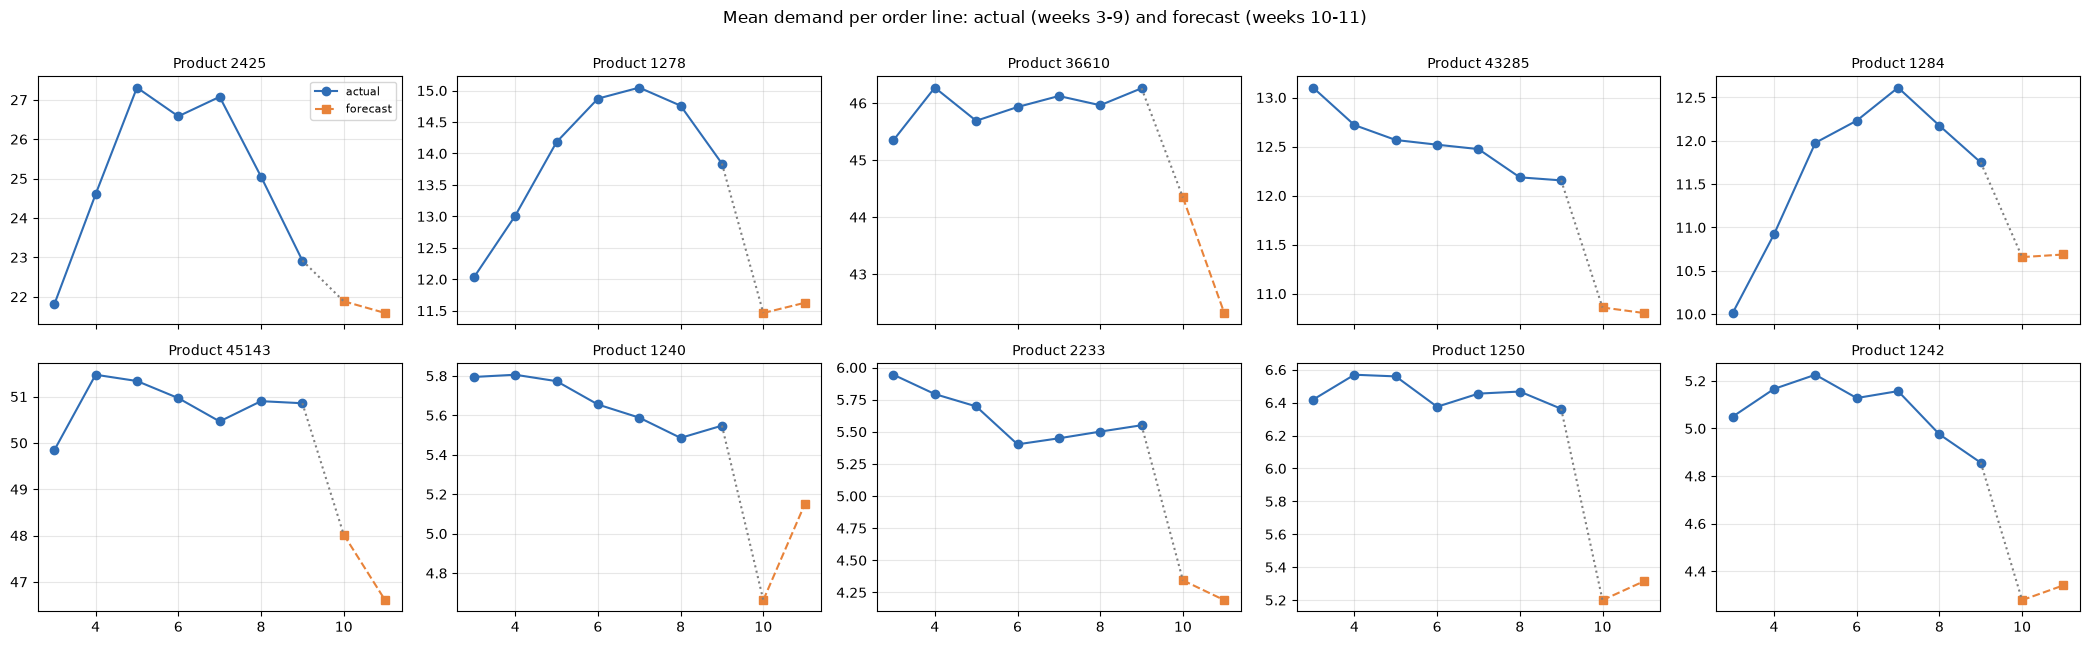

In [11]:
hist = pd.read_csv(config.FINAL_WEEKLY_PATH)
n = len(tab); ncols = 5; nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 3.2 * nrows), sharex=True, squeeze=False)
for ax, pid in zip(axes.ravel(), tab.index):
    h = hist[hist.Product_ID == pid]; f = g[g.Product_ID == pid]
    ax.plot(h.Week, h["mean"], "o-", color="#2f6db5", label="actual")
    ax.plot(f.Week, f.Predicted_Mean, "s--", color="#e8833a", label="forecast")
    if len(h) and len(f): ax.plot([h.Week.iloc[-1], f.Week.iloc[0]], [h["mean"].iloc[-1], f.Predicted_Mean.iloc[0]], ":", color="gray")
    ax.set_title(f"Product {pid}", fontsize=10); ax.grid(alpha=.3)
for ax in axes.ravel()[n:]: ax.axis("off")
axes[0, 0].legend(fontsize=8); fig.suptitle("Mean demand per order line: actual (weeks 3-9) and forecast (weeks 10-11)", y=1.0)
plt.tight_layout(); plt.show()
json.dump({"test_table": TABLE, "rows_total": int(len(pred)), "rows_by_week": {int(w): int(len(d)) for w, d in test.items()},
           "n_products": int(pred.Product_ID.nunique()), "labels_available": bool(has_target),
           "coverage_pct_new": {int(w): {c: float(cov.loc[w, c]) for c in cov.columns[1:]} for w in cov.index},
           "predicted_total_by_week": {int(w): float(v) for w, v in pred.groupby("Week").Predicted_Demand.sum().items()}},
          open(config.FINAL_TEST_SUMMARY_PATH, "w"), indent=2)

## 7. Summary
- Forecasts for **weeks 10 and 11** were produced for every row of `test_filtered` and aggregated per product and week (section 4) and per customer × product (section 4b).
- Expected accuracy: see the R² table in section 5 (week 10 ≈ one week ahead, week 11 ≈ two weeks ahead).
- Files: `outputs/final/test_predictions_rows.csv` (id + forecast), `test_predictions_by_product_week.csv`, `customer_x_product_predicted_week10/11.csv`.
- Limits: linear model, test labels hidden, week 11 uses history that ends at week 9 (one week older than for week 10).